# HW 4: Spatial Attention for CNNs

### 20 points + up to 30 extra credit

##### Due: Tuesday. August 12th (11:59pm)

In this assignment you will extend your convolutional neural network from Homework 3 by adding an attention mechanism. We will start with the same dataset as before (MNIST) and work our way up to new datasets. 

You may download this assignment as a Jupyter notebook file from Submitty. 

**Note:** This assignent is more focused on theoretical understanding and analysis than results. If you are able to achieve good results, you are eligible for up to 30 points of extra credit (towards your homework score, which is 35% of your grade). However, **your attention model does not need to outperform your CNN** in order to earn full credit.

#### Provided utility code

These functions load various image datasets. MNIST is the smallest/simplest, FashionMNIST is somewhat more complex, CIFAR10 is more complex than that, and CIFAR100 is the largest.

In [178]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision.datasets import MNIST, FashionMNIST
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
SEED = 42
torch.manual_seed(SEED)

### Dataset loader utility functions ###

def get_dataset(name, batch_size=64):
    if name == "MNIST":
        mean, std = (0.1307,), (0.3081,)
        in_channels, image_size, num_classes = 1, 28, 10
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])
        dataset_cls = datasets.MNIST

    elif name == "FashionMNIST":
        mean, std = (0.2860,), (0.3530,)
        in_channels, image_size, num_classes = 1, 28, 10
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])
        dataset_cls = datasets.FashionMNIST

    elif name == "CIFAR10":
        mean = [0.4914, 0.4822, 0.4465]
        std =  [0.2470, 0.2435, 0.2616]
        in_channels, image_size, num_classes = 3, 32, 10
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])
        dataset_cls = datasets.CIFAR10

    elif name == "CIFAR100":
        mean = [0.5071, 0.4867, 0.4408]
        std =  [0.2675, 0.2565, 0.2761]
        in_channels, image_size, num_classes = 3, 32, 100
        transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean, std),
        ])
        dataset_cls = datasets.CIFAR100

    else:
        raise ValueError(f"Unknown dataset: {name}")

    train_raw = dataset_cls(root="./data", train=True, download=True, transform=transform)
    test_raw  = dataset_cls(root="./data", train=False, download=True, transform=transform)

    train_data, val_data = random_split(train_raw, [int(0.9 * len(train_raw)), len(train_raw) - int(0.9 * len(train_raw))],
                                        generator=torch.Generator().manual_seed(42))

    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_data, batch_size=batch_size)
    test_loader  = DataLoader(test_raw, batch_size=batch_size)

    return train_loader, val_loader, test_loader, in_channels, image_size, num_classes

### Training / Evaluation utility functions ###

def train_one_epoch(model, train_loader, val_loader, optimizer, criterion, device):
    model.train()
    total_loss, correct = 0, 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()

    avg_loss = total_loss / len(train_loader.dataset)
    accuracy = correct / len(train_loader.dataset)

    # Run validation immediately after each epoch
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)
    return avg_loss, accuracy, val_loss, val_acc

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * inputs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()

    avg_loss = total_loss / len(dataloader.dataset)
    accuracy = correct / len(dataloader.dataset)
    return avg_loss, accuracy


## Part 1: Attention 

### (10 points)

#### Baseline CNN

To start, we'll use the CNN you created from HW3 -- modified slightly. We've provided a "dummy" CNN to show how you might modify your original CNN -- essentially, you are using the hidden layers you created, but not the final steps of compressing them into an output. This is because we will need that information in order to implement attention!

Paste the PyTorch class defining your best performing CNN from Homework 3 here. Make sure the network returns a feature map (not flattened) so that you can apply attention over the spatial dimensions. If your original model flattened the tensor before the classifier, separate the convolutional part from the classifier so you can access the feature map.

It is recoemmended that your CNN outptu an unflattened tensor of shape \[B, C, H, W\]: 
- B: the batch size: how many examples are processed together in one forward/backward pass.
- C: the number of channels: for raw images this is 1 for grayscale or 3 for RGB, and for intermediate feature maps it’s the number of filters output by a convolution layer.
- H: the height of each image or feature map, in pixels.
- W: the width of each image or feature map, in pixels.

In [179]:
# TODO: Replace this dummy CNN with your Homework 3 model.
# IMPORTANT: Modify your model to:
#  (1) Remove flattening and FC layers
#  (2) Return [B, C, H, W] feature maps
#  B - Number of batches
#  (3) Preserve enough spatial resolution (avoid aggressive pooling)

class BaseCNN(nn.Module):
    def __init__(self, in_channels):
        super(BaseCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 4, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(4, 16, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(16, 64, kernel_size=3, stride=1, padding=1)

        self.maxpooling = nn.MaxPool2d(2, 2)
            
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = self.maxpooling(x)
        
        return x

## Outputs a feature map of size [B = 16, 64, 15, 15]

#### Fully connected (FC) CNN

This CNN uses the BaseCNN in a standard fully connected neural net to compute results. We'll just use it for comparison, and you can also use it to confirm your BaseCNN implementation is correct.

In [180]:
class FCClassifier(nn.Module):
    def __init__(self, base_cnn, feature_shape=(64, 14, 14), num_classes=10):
        super().__init__()
        self.base = base_cnn
        C, H, W = feature_shape
        self.fc1 = nn.Linear(C * H * W, 128)
        self.out = nn.Linear(128, num_classes)

    def forward(self, x):
        feats = self.base(x)                  # [B, C, H, W]
        flat = feats.view(x.size(0), -1)      # [B, C * H * W]
        x = F.relu(self.fc1(flat))
        return self.out(x)


#### Spatial Attention

The code below defines a new network, AttentionCNN, which adds an attention mechanism and additional layers to BaseCNN.

Your task is to replace the "dummy" attention implementation below with your own attention function (the dummy function assigns all attention scores as equal to one). In additon, you will likely need to add additional layers to the network, or adjust it as needed.

To start, we recommend a simple attention mechanism: Compute attention scores by taking the average over all channels in the flattened input features (the matrix "flat"). We'll be modifying this to add more complex attention mechanisms as we go, however.

In [181]:
class AttentionCNN(nn.Module):
    def __init__(self, base_cnn, num_features, num_classes=10):
        super().__init__()

        # By default: first "layer" is base_cnn, then it computes attention
        self.base = base_cnn

        # after attention is computed: uses a couple more layers
        self.fc1 = nn.Linear(num_features, 128)
        self.fc2 = nn.Linear(128, 96)
        self.fc3 = nn.Linear(96, 64)

        self.dropout = nn.Dropout(0.5)
        self.out = nn.Linear(64, num_classes)

    def forward(self, x):
        # TODO: Replace the dummy example below with your own implementation
        # Pass the input through the base CNN to extract feature maps
        feats = self.base(x) # Shape: [B, C, H, W]
    
        # Unpack dimensions for clarity
        B, C, H, W = feats.shape
    
        # Flatten the spatial dimensions (H and W) into a single dimension
        # This treats each spatial position as a separate "token" for attention
        flat = feats.view(B, C, H * W) # [B, C, H*W]

        ## Compute attention score by taking average over all channels in the flatten input features.
        attn_scores = flat.mean(dim=1)

        ## Then, we apply softmax to obtain the normalized attention weights (We need them to be positive and sum to 1).
        attn_weights = torch.softmax(attn_scores, dim=1)

        ## Then, we apply the weights to the features.
        weighted = flat * attn_weights.unsqueeze(1)

        ## Then, we sum over the spatial dimension so that we get a single feature vector per sample.
        ## Similar to average pooling over the spatial positions.
        agg = weighted.sum(dim=2)

        x = F.relu(self.fc1(agg))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = F.relu(self.fc3(x))
        x = self.dropout(x)

        return self.out(x)

        # # === DUMMY ATTENTION IMPLEMENTATION ===
        # # Initialize dummy attention scores as all ones
        # attn_scores = torch.ones(B, H * W, device=feats.device) # [B, H*W]
    
        # # Apply softmax to obtain normalized attention weights
        # # Because all scores are equal, softmax will output uniform weights
        # attn_weights = torch.softmax(attn_scores, dim=1) # [B, H*W]
    
        # # Apply attention weights to the feature map
        # # First, expand attn_weights to [B, 1, H*W] to match flat's shape for broadcasting
        # weighted = flat * attn_weights.unsqueeze(1) # [B, C, H*W]
    
        # # Aggregate (sum) over the spatial dimension to get a global feature vector per sample
        # # Since weights are uniform, this is equivalent to average pooling over spatial positions
        # agg = weighted.sum(dim=2) # [B, C]

        # x = F.relu(self.fc1(agg))
        # x = self.dropout(x)


#### Training and testing

Evaluate your AttentionCNN on MNIST, and compare it to the basic FCClassifier. What do you see? USe Use matplotlib to visualize the training loss and validation accuracy across epochs for both of the models. This will help you see whether the models are improving, and whether they have started to overfit.

(Don't expect AttentionCNN to outperform the FC  model here unless you've added a very complex attention mechanism! This dataset is simple enough that attention may not add as much value as you might expect.)

Training Fully Connected Baseline...
[FC] Epoch 1: Train Acc = 0.9558, Val Acc = 0.9827
[FC] Epoch 2: Train Acc = 0.9873, Val Acc = 0.9862
[FC] Epoch 3: Train Acc = 0.9919, Val Acc = 0.9850
[FC] Epoch 4: Train Acc = 0.9940, Val Acc = 0.9870
[FC] Epoch 5: Train Acc = 0.9952, Val Acc = 0.9883
[FC] Test Accuracy = 0.9898


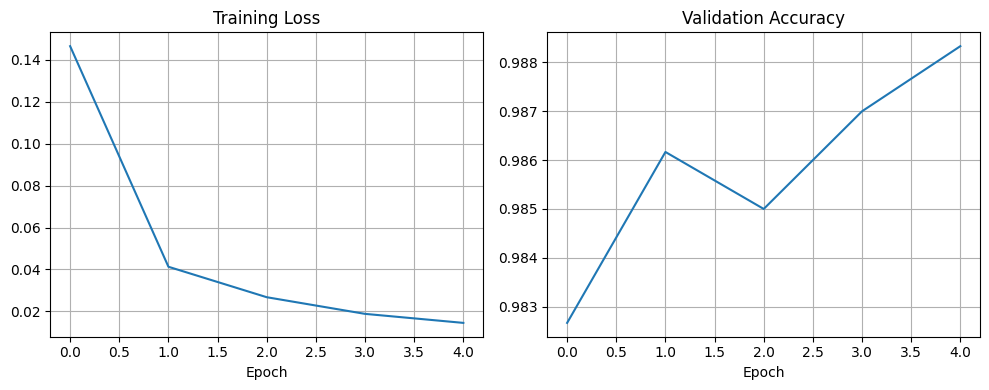

Training Attention Model...
[ATTEN] Epoch 1: Train Acc = 0.2508, Val Acc = 0.3080
[ATTEN] Epoch 2: Train Acc = 0.3444, Val Acc = 0.4670
[ATTEN] Epoch 3: Train Acc = 0.5010, Val Acc = 0.6902
[ATTEN] Epoch 4: Train Acc = 0.6650, Val Acc = 0.7473
[ATTEN] Epoch 5: Train Acc = 0.7336, Val Acc = 0.8283
[ATTEN] Epoch 6: Train Acc = 0.7835, Val Acc = 0.8583
[ATTEN] Epoch 7: Train Acc = 0.8185, Val Acc = 0.8838
[ATTEN] Test Accuracy = 0.8946


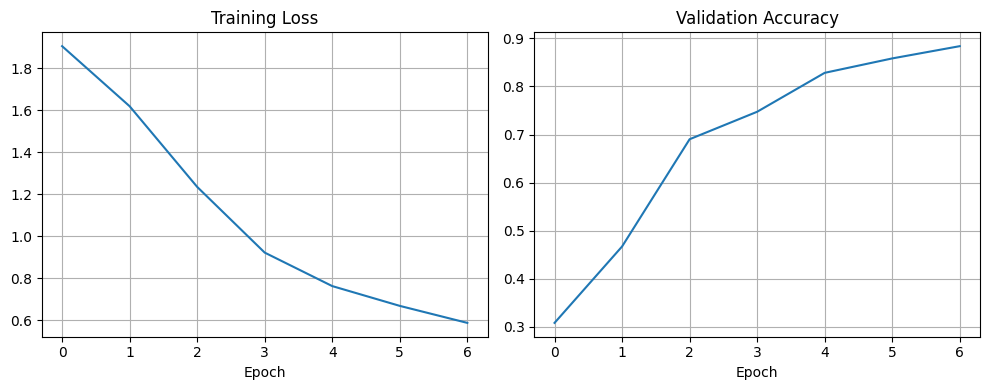

In [182]:
# Use the utility functions to load the MNIST dataset, train, and test.
# We've shown how to use them with FCClassifier below.

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load MNIST and get dataset info
train_loader, val_loader, test_loader, in_channels, image_size, num_classes = get_dataset("MNIST",batch_size=64)
criterion = nn.CrossEntropyLoss()

# Instantiate base feature extractor
base_model_fc = BaseCNN(in_channels).to(device)
# Train FC baseline
print("Training Fully Connected Baseline...")
fc_model = FCClassifier(base_model_fc, feature_shape=(64, image_size // 2, image_size // 2), num_classes=num_classes).to(device)
fc_optimizer = torch.optim.Adam(fc_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(fc_model, train_loader, val_loader, fc_optimizer, criterion, device)
    print(f"[FC] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(fc_model, test_loader, criterion, device)
print(f"[FC] Test Accuracy = {test_acc:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

# TODO: Train Attention-based model
print("Training Attention Model...")
base_model_attn = BaseCNN(in_channels).to(device)
attention_model = AttentionCNN(base_model_attn, num_features=64, num_classes=num_classes).to(device)
attention_optimizer = torch.optim.Adam(attention_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 8):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(attention_model, train_loader, val_loader, attention_optimizer, criterion, device)
    print(f"[ATTEN] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(attention_model, test_loader, criterion, device)
print(f"[ATTEN] Test Accuracy = {test_acc:.4f}")

# TODO: Use matplotlib to plot tr_loss, val_acc over time for fc_model and your attention model.
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

#### Visualize the attention weights 

To confirm that your attention weights correspond to the most salient parts of the image, pick a few examples from the test set and visualize their attention maps. Overlay the attention weights on the input image to see which pixels the model focuses on. Hint: you can obtain the attention weights by copying the code from your forward method and applying it to one image.

See here for an example of what a correct attention map looks like: [hw4-example-attention-map.png](https://submitty.cs.rpi.edu/courses/u25/csci4150/course_material/Homework/Homework%204/hw4-example-attention-map.png).

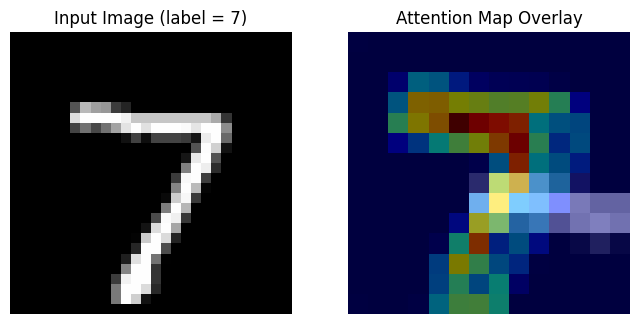

In [183]:
# TODO: visualize the attention map for a sample image
# We'll take the first test example as a demonstration

#TODO: Replace with your attention model
model = attention_model

model.eval()
with torch.no_grad():
    sample_img, sample_label = test_loader.dataset[0]
    sample_tensor = sample_img.unsqueeze(0).to(device)
    # Get feature map from the base CNN
    feats = fc_model.base(sample_tensor)
    B, C, H, W = feats.shape

    # TODO: Replace this code with code to show your actual attention weights
    flat = feats.view(B, C, H * W) # [B, C, H*W]

    ## Compute attention score by taking average over all channels in the flatten input features.
    attn_scores = flat.mean(dim=1)

    ## Then, we apply softmax to obtain the normalized attention weights (We need them to be positive and sum to 1).
    attn_weights = torch.softmax(attn_scores, dim=1)
    
    attn_map = attn_weights.view(H, W).cpu().numpy()
    # Normalize attention map for better visualization
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())

    # Plot input image
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(sample_img.squeeze(0), cmap='gray')
    ax[0].set_title(f'Input Image (label = {sample_label})')
    ax[0].axis('off')
    # Plot attention map overlay
    ax[1].imshow(sample_img.squeeze(0), cmap='gray')
    ax[1].imshow(attn_map, cmap='jet', alpha=0.5)
    ax[1].set_title('Attention Map Overlay')
    ax[1].axis('off')

## Part 2: Testing and iteration

### (10 points)

As you might expect, attention doesn't make a huge difference for a small dataset like MNIST. Try running the other three datasets: Fashion‑MNIST, CIFAR10, and CIFAR100.

For each dataset:
- Run both the baseline fully connected model and the simple attention model
- Visualize the attention weights
- Answer the questions below

Training Fully Connected Baseline...
[FC] Epoch 1: Train Acc = 0.8523, Val Acc = 0.8948
[FC] Epoch 2: Train Acc = 0.9101, Val Acc = 0.9062
[FC] Epoch 3: Train Acc = 0.9270, Val Acc = 0.9137
[FC] Epoch 4: Train Acc = 0.9403, Val Acc = 0.9163
[FC] Epoch 5: Train Acc = 0.9536, Val Acc = 0.9225
[FC] Test Accuracy = 0.9198


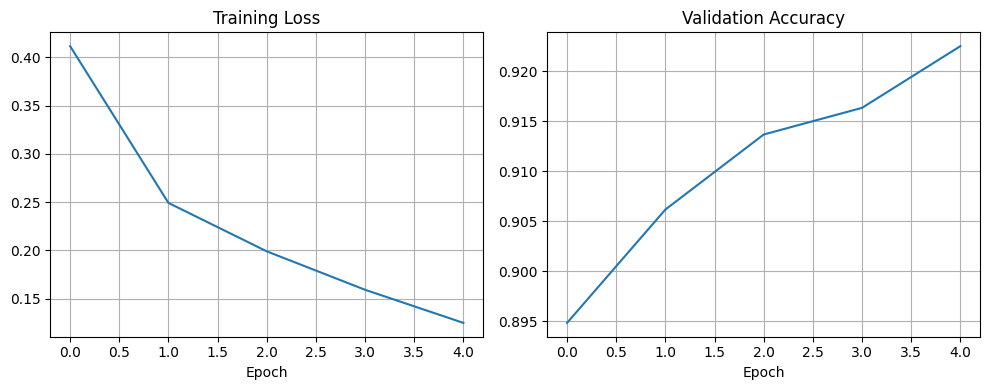

[Fashion-MNIST] Training Attention Model...
[Fashion-MNIST ATTEN] Epoch 1: Train Acc = 0.3004, Val Acc = 0.4862
[Fashion-MNIST ATTEN] Epoch 2: Train Acc = 0.4955, Val Acc = 0.5922
[Fashion-MNIST ATTEN] Epoch 3: Train Acc = 0.5692, Val Acc = 0.6332
[Fashion-MNIST ATTEN] Epoch 4: Train Acc = 0.6283, Val Acc = 0.7022
[Fashion-MNIST ATTEN] Epoch 5: Train Acc = 0.6731, Val Acc = 0.7365
[Fashion-MNIST ATTEN] Test Accuracy = 0.7327


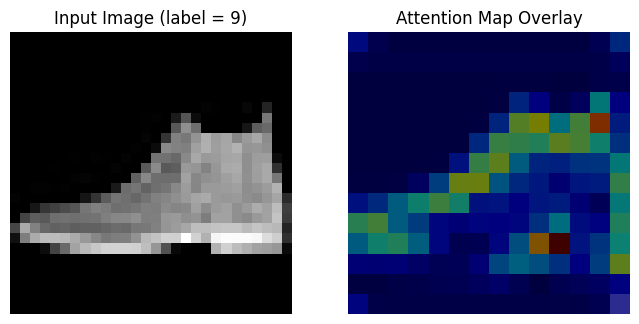

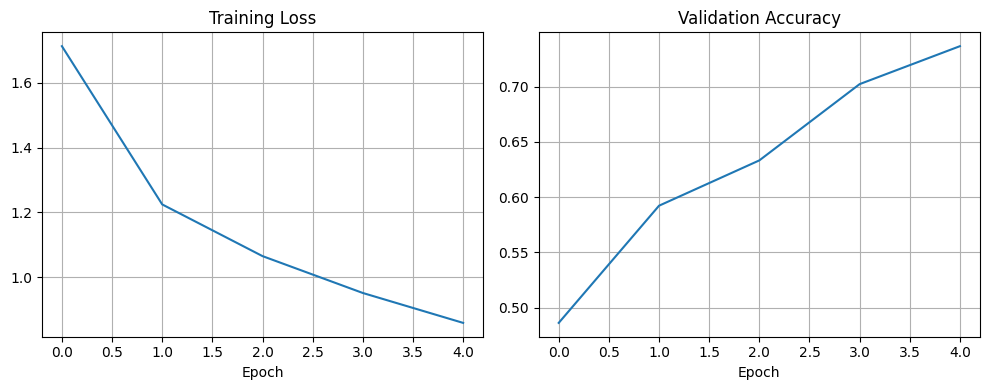

In [184]:
# Put code to run your tests and visualize your results here

## Fashion-MNIST
train_loader, val_loader, test_loader, in_channels, image_size, num_classes = get_dataset("FashionMNIST", batch_size=64)

print("Training Fully Connected Baseline...")
base_model_fc_2 = BaseCNN(in_channels).to(device)
fc_model = FCClassifier(base_model_fc_2, feature_shape=(64, image_size // 2, image_size // 2), num_classes=num_classes).to(device)
fc_optimizer = torch.optim.Adam(fc_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(fc_model, train_loader, val_loader, fc_optimizer, criterion, device)
    print(f"[FC] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(fc_model, test_loader, criterion, device)
print(f"[FC] Test Accuracy = {test_acc:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

print("[Fashion-MNIST] Training Attention Model...")

base_model_fashion = BaseCNN(in_channels).to(device)
attention_model = AttentionCNN(base_model_fashion, num_features=64, num_classes=num_classes).to(device)
attention_optimizer = torch.optim.Adam(attention_model.parameters(), lr=0.001)

FashionMNIST_train_losses = []
FashionMNIST_val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(attention_model, train_loader, val_loader, attention_optimizer, criterion, device)
    print(f"[Fashion-MNIST ATTEN] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    FashionMNIST_train_losses.append(tr_loss)
    FashionMNIST_val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(attention_model, test_loader, criterion, device)
print(f"[Fashion-MNIST ATTEN] Test Accuracy = {test_acc:.4f}")
model = attention_model

model.eval()
with torch.no_grad():
    sample_img, sample_label = test_loader.dataset[0]
    sample_tensor = sample_img.unsqueeze(0).to(device)
    # Get feature map from the base CNN
    feats = fc_model.base(sample_tensor)
    B, C, H, W = feats.shape

    # TODO: Replace this code with code to show your actual attention weights
     ## Compute attention score by taking average over all channels in the flatten input features.
    flat = feats.view(B, C, H * W) # [B, C, H*W]
    attn_scores = flat.mean(dim=1)
    attn_weights = torch.softmax(attn_scores, dim=1)
    
    attn_map = attn_weights.view(H, W).cpu().numpy()
    # Normalize attention map for better visualization
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())

    # Plot input image
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(sample_img.squeeze(0), cmap='gray')
    ax[0].set_title(f'Input Image (label = {sample_label})')
    ax[0].axis('off')
    # Plot attention map overlay
    ax[1].imshow(sample_img.squeeze(0), cmap='gray')
    ax[1].imshow(attn_map, cmap='jet', alpha=0.5)
    ax[1].set_title('Attention Map Overlay')
    ax[1].axis('off')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(FashionMNIST_train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(FashionMNIST_val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

Training Fully Connected Baseline...
[FC] Epoch 1: Train Acc = 0.4688, Val Acc = 0.5462
[FC] Epoch 2: Train Acc = 0.6366, Val Acc = 0.6228
[FC] Epoch 3: Train Acc = 0.7063, Val Acc = 0.6524
[FC] Epoch 4: Train Acc = 0.7608, Val Acc = 0.6600
[FC] Epoch 5: Train Acc = 0.8070, Val Acc = 0.6678
[FC] Test Accuracy = 0.6631


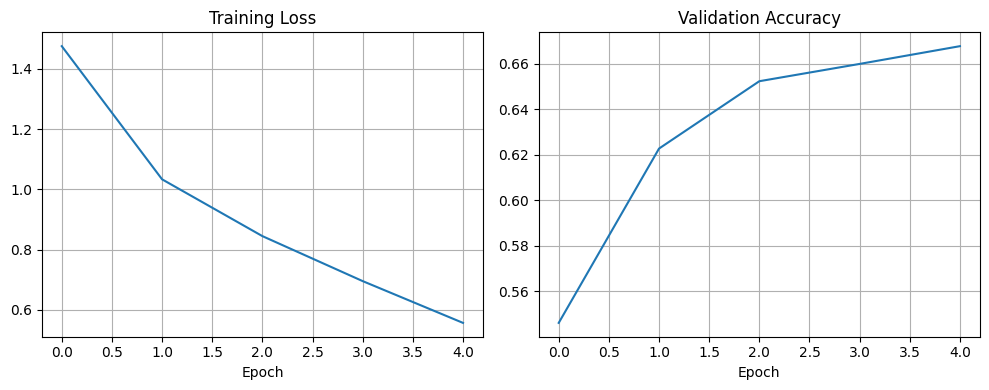

[CIFAR10 ATTEN] Training Attention Model...
[CIFAR10 ATTEN] Epoch 1: Train Acc = 0.1888, Val Acc = 0.2546
[CIFAR10 ATTEN] Epoch 2: Train Acc = 0.2618, Val Acc = 0.3094
[CIFAR10 ATTEN] Epoch 3: Train Acc = 0.2862, Val Acc = 0.3118
[CIFAR10 ATTEN] Epoch 4: Train Acc = 0.2999, Val Acc = 0.3366
[CIFAR10 ATTEN] Epoch 5: Train Acc = 0.3122, Val Acc = 0.3462


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7830755..2.0942786].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7830755..2.0942786].


[CIFAR10 ATTEN] Test Accuracy = 0.3489


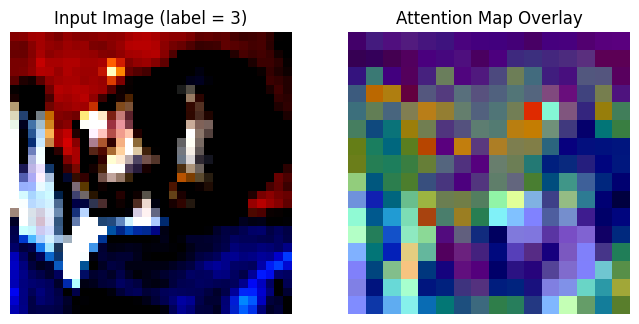

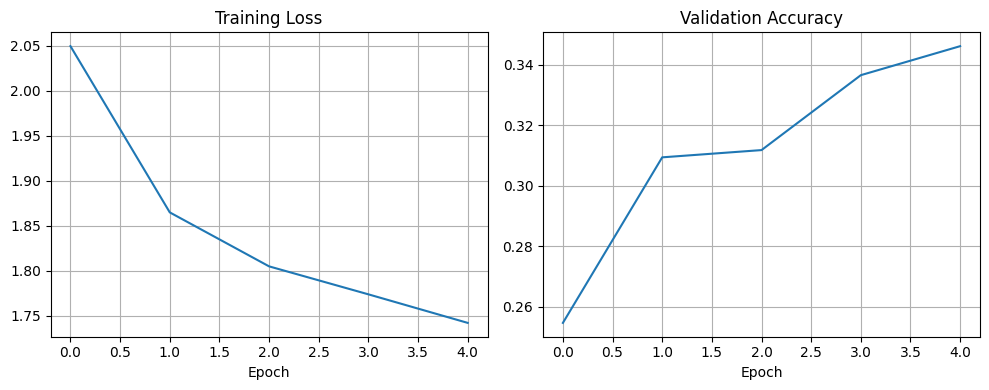

In [185]:
## CIFAR10
train_loader, val_loader, test_loader, in_channels, image_size, num_classes = get_dataset("CIFAR10", batch_size=64)
base_model_fc_3 = BaseCNN(in_channels).to(device)

print("Training Fully Connected Baseline...")
fc_model = FCClassifier(base_model_fc_3, feature_shape=(64, image_size // 2, image_size // 2), num_classes=num_classes).to(device)
fc_optimizer = torch.optim.Adam(fc_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(fc_model, train_loader, val_loader, fc_optimizer, criterion, device)
    print(f"[FC] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(fc_model, test_loader, criterion, device)
print(f"[FC] Test Accuracy = {test_acc:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

print("[CIFAR10 ATTEN] Training Attention Model...")
base_model_CIFAR10 = BaseCNN(in_channels).to(device)
attention_model = AttentionCNN(base_model_CIFAR10, num_features=64, num_classes=num_classes).to(device)
attention_optimizer = torch.optim.Adam(attention_model.parameters(), lr=0.001)

CIFAR10_train_losses = []
CIFAR10_val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(attention_model, train_loader, val_loader, attention_optimizer, criterion, device)
    print(f"[CIFAR10 ATTEN] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    CIFAR10_train_losses.append(tr_loss)
    CIFAR10_val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(attention_model, test_loader, criterion, device)
print(f"[CIFAR10 ATTEN] Test Accuracy = {test_acc:.4f}")
model = attention_model

model.eval()
with torch.no_grad():
    sample_img, sample_label = test_loader.dataset[0]
    sample_tensor = sample_img.unsqueeze(0).to(device)
    # Get feature map from the base CNN
    feats = fc_model.base(sample_tensor)
    B, C, H, W = feats.shape

    # TODO: Replace this code with code to show your actual attention weights
     ## Compute attention score by taking average over all channels in the flatten input features.
    flat = feats.view(B, C, H * W) # [B, C, H*W]
    attn_scores = flat.mean(dim=1)
    attn_weights = torch.softmax(attn_scores, dim=1)
    
    attn_map = attn_weights.view(H, W).cpu().numpy()
    # Normalize attention map for better visualization
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())

    # Plot input image
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    img = sample_img.squeeze(0).permute(1, 2, 0).cpu().numpy()
    
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'Input Image (label = {sample_label})')
    ax[0].axis('off')

    # Plot attention map overlay
    ax[1].imshow(img, cmap='gray')
    ax[1].imshow(attn_map, cmap='jet', alpha=0.5)
    ax[1].set_title('Attention Map Overlay')
    ax[1].axis('off')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(CIFAR10_train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(CIFAR10_val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

Training Fully Connected Baseline...
[FC] Epoch 1: Train Acc = 0.1433, Val Acc = 0.2314
[FC] Epoch 2: Train Acc = 0.2865, Val Acc = 0.2906
[FC] Epoch 3: Train Acc = 0.3780, Val Acc = 0.3260
[FC] Epoch 4: Train Acc = 0.4619, Val Acc = 0.3342
[FC] Epoch 5: Train Acc = 0.5490, Val Acc = 0.3348
[FC] Test Accuracy = 0.3386


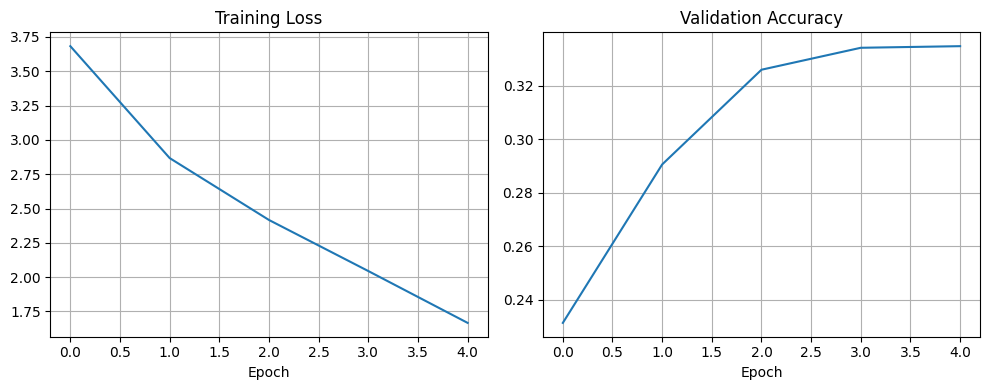

[CIFAR100 ATTEN] Training Attention Model...
[CIFAR100 ATTEN] Epoch 1: Train Acc = 0.0179, Val Acc = 0.0230
[CIFAR100 ATTEN] Epoch 2: Train Acc = 0.0279, Val Acc = 0.0368
[CIFAR100 ATTEN] Epoch 3: Train Acc = 0.0417, Val Acc = 0.0654
[CIFAR100 ATTEN] Epoch 4: Train Acc = 0.0522, Val Acc = 0.0726
[CIFAR100 ATTEN] Epoch 5: Train Acc = 0.0582, Val Acc = 0.0788


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1788939..2.025353].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1788939..2.025353].


[CIFAR100 ATTEN] Test Accuracy = 0.0810


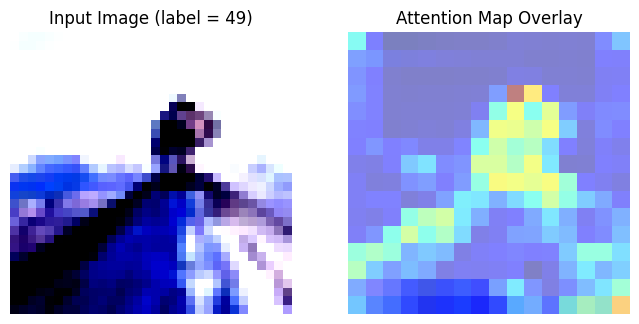

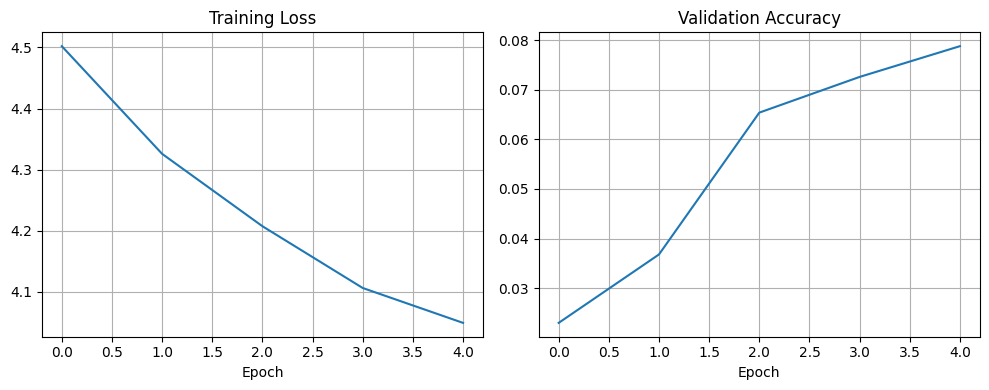

In [186]:
## CIFAR100
train_loader, val_loader, test_loader, in_channels, image_size, num_classes = get_dataset("CIFAR100", batch_size=64)
base_model_fc_4 = BaseCNN(in_channels).to(device)

print("Training Fully Connected Baseline...")
fc_model = FCClassifier(base_model_fc_4, feature_shape=(64, image_size // 2, image_size // 2), num_classes=num_classes).to(device)
fc_optimizer = torch.optim.Adam(fc_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(fc_model, train_loader, val_loader, fc_optimizer, criterion, device)
    print(f"[FC] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(fc_model, test_loader, criterion, device)
print(f"[FC] Test Accuracy = {test_acc:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

print("[CIFAR100 ATTEN] Training Attention Model...")
base_model_CIFAR100 = BaseCNN(in_channels).to(device)
attention_model = AttentionCNN(base_model_CIFAR100, num_features=64, num_classes=num_classes).to(device)
attention_optimizer = torch.optim.Adam(attention_model.parameters(), lr=0.001)

CIFAR100_train_losses = []
CIFAR100_val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(attention_model, train_loader, val_loader, attention_optimizer, criterion, device)
    print(f"[CIFAR100 ATTEN] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    CIFAR100_train_losses.append(tr_loss)
    CIFAR100_val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(attention_model, test_loader, criterion, device)
print(f"[CIFAR100 ATTEN] Test Accuracy = {test_acc:.4f}")
model = attention_model

model.eval()
with torch.no_grad():
    sample_img, sample_label = test_loader.dataset[0]
    sample_tensor = sample_img.unsqueeze(0).to(device)
    # Get feature map from the base CNN
    feats = fc_model.base(sample_tensor)
    B, C, H, W = feats.shape

    # TODO: Replace this code with code to show your actual attention weights
     ## Compute attention score by taking average over all channels in the flatten input features.
    flat = feats.view(B, C, H * W) # [B, C, H*W]
    attn_scores = flat.mean(dim=1)
    attn_weights = torch.softmax(attn_scores, dim=1)
    
    attn_map = attn_weights.view(H, W).cpu().numpy()
    # Normalize attention map for better visualization
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())

    # Plot input image
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    img = sample_img.squeeze(0).permute(1, 2, 0).cpu().numpy()
    ax[0].imshow(img, cmap='gray')
    ax[0].set_title(f'Input Image (label = {sample_label})')
    ax[0].axis('off')
    
    # Plot attention map overlay
    ax[1].imshow(img, cmap='gray')
    ax[1].imshow(attn_map, cmap='jet', alpha=0.5)
    ax[1].set_title('Attention Map Overlay')
    ax[1].axis('off')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(CIFAR100_train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(CIFAR100_val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

#### Analysis

Answer the following questions in this markdown cell:

1. Did the attention mechanism improve your model’s performance or training speed compared to your original CNN? Why or why not?

For performance on the MNIST dataset only, the performance could definitely match the CNN's performance, as for the training speed it is slower compared to my original CNN. Probably xbecause of the need to calculate so many weights from the feature maps, its a lot slower compared to just the CNN. The performance at the start is lackluster, maybe ~25% accuracy but as it goes on it eventually reached ~90% accuracy in only 5 epochs, which shows massive improvement compared to the CNN which starts at a high accuracy but sort of hovers around that general area.

2. What do your attention maps reveal about which parts of the images are most informative for classification?

The most informative parts of the number 7 from the attention map are definitely the line at the top, and the slant of the 7, these are its most notable features. Everything that doesn't trace the 7 has no attention which is very good for our model, but some parts that may overlap with other numbers are also generally not given much attention.

3. After a certain point, neither model is particularly effective -- but we know that this is only a simple implementation now. What modifications could you make to the model structure (the layers in BaseCNN or AttentionCNN) to better make use of attention? And what modifications can we make to the attention mechanism itself to be more useful for classifying these images? Come up with at least three different methods.

Currently, we only use a single-head attention mechanism where we get the attention scores, weights and then apply it to our feature map. We can definitely improve it by adding more attention heads and turning our AttentionCNN into a multi-head attention model. We can also improve our attention mechanism. The current one used is extremely simple by averaging all the channels in the flatten feature map to get our attention scores. We could use a MLP to learn and find better scores and weights. In BaseCNN, I use 3 convolution layers and only do pooling once as we wanted to preserve as much spacial resolution as we could. We could definitely add more layers and find the balance between convolution layers, pooling and preserving spacial res.

## Part 3: Extra credit

Try to see if you can implement improvements to your attention model. Are you able to outperform the baseline fully connected model ? You are allowed to edit either BaseCNN or AttentionCNN, but when testing you should use the same implementation of BaseCNN and FCClassifier. 

You will recieve extra credit for any of the following: 

- Up to +30 points: Implementations for improvements that allow AttentionCNN to outperform FCClassifier on any of the datasets.
- Up to +15 points: Implementations that successfully improve the AttentionCNN's performance, but have not resulted in AttentionCNN outperforming FCClassifier.
- Up to +5 points: Attempted implementation of AttentionCNN improvements

List any extra credit implementations you have attempted below, and which of the three categories they fall in.
- Tweaking AttentionCNN parameters such as dropout rate (from 0.5 to 0.3) and increasing # of epochs (from 5 to 7)
  - Improvement: ~73% accuract on MNIST --> ~93% accuracy on MNIST
  - Category: Successfully improves AttentionCNN performance, but does not outperform FCClassifier

- AttentionCNN attention mechanism improved from averaging all channels to using a fully connected layer to compute attention scores from channel features, allowing the model to learn how to weigh each spacial location.
  - Improvement: ~93% accuracy on MNIST --> ~95% accuracy on MNIST
  - Category: Successfully improves AttentionCNN performance, but does not outperform FCClassifier



Training Attention Model...
[ATTEN] Epoch 1: Train Acc = 0.3073, Val Acc = 0.4550
[ATTEN] Epoch 2: Train Acc = 0.6080, Val Acc = 0.7365
[ATTEN] Epoch 3: Train Acc = 0.7613, Val Acc = 0.8655
[ATTEN] Epoch 4: Train Acc = 0.8508, Val Acc = 0.8923
[ATTEN] Epoch 5: Train Acc = 0.8844, Val Acc = 0.9237
[ATTEN] Epoch 6: Train Acc = 0.9053, Val Acc = 0.9062
[ATTEN] Epoch 7: Train Acc = 0.9160, Val Acc = 0.9382
[ATTEN] Test Accuracy = 0.9464


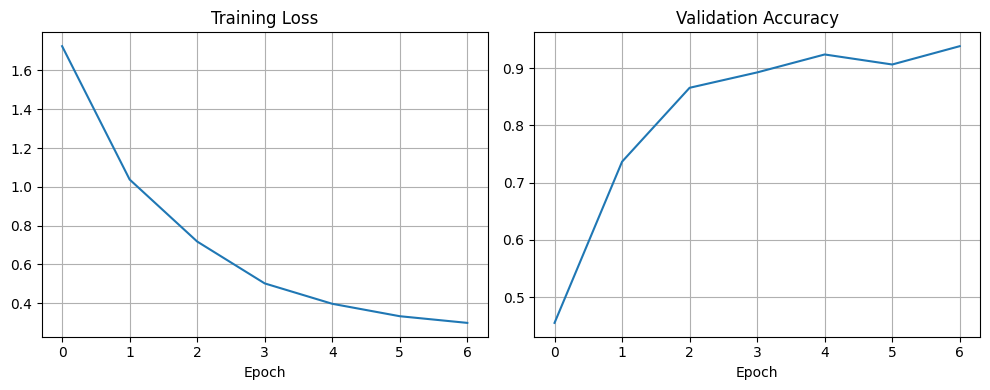

In [197]:


# Copy/paste AttentionCNN, BaseCNN, and FCClassifier below to modify if you are attempting extra credit:
class BaseCNN(nn.Module):
    def __init__(self, in_channels):
        super(BaseCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 4, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(4, 16, kernel_size=3, stride=1, padding=1)
        self.conv3 = nn.Conv2d(16, 64, kernel_size=3, stride=1, padding=1)

        self.maxpooling = nn.MaxPool2d(2, 2)
            
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = F.relu(self.conv3(x))
        x = self.maxpooling(x)
        
        return x

## Outputs a feature map of size [B = 16, 64, 15, 15]

class FCClassifier(nn.Module):
    def __init__(self, base_cnn, feature_shape=(64, 14, 14), num_classes=10):
        super().__init__()
        self.base = base_cnn
        C, H, W = feature_shape
        self.fc1 = nn.Linear(C * H * W, 128)
        self.out = nn.Linear(128, num_classes)

    def forward(self, x):
        feats = self.base(x)                  # [B, C, H, W]
        flat = feats.view(x.size(0), -1)      # [B, C * H * W]
        x = F.relu(self.fc1(flat))
        return self.out(x)

class AttentionCNN(nn.Module):
    def __init__(self, base_cnn, num_features, num_classes=10):
        super().__init__()

        # By default: first "layer" is base_cnn, then it computes attention
        self.base = base_cnn
        
        self.attn_fc = nn.Linear(num_features, 1)

        # after attention is computed: uses a couple more layers
        self.fc1 = nn.Linear(num_features, 128)
        self.fc2 = nn.Linear(128, 96)
        self.fc3 = nn.Linear(96, 64)

        self.dropout = nn.Dropout(0.3)
        self.out = nn.Linear(64, num_classes)

    def forward(self, x):
        # Pass the input through the base CNN to extract feature maps
        feats = self.base(x) # Shape: [B, C, H, W]
    
        # Unpack dimensions for clarity
        B, C, H, W = feats.shape
    
        # Flatten the spatial dimensions (H and W) into a single dimension
        # This treats each spatial position as a separate "token" for attention
        flat = feats.view(B, C, H * W) # [B, C, H*W]
        flat_transpose = flat.permute(0, 2, 1)

        ## Compute attention score by taking average over all channels in the flatten input features.
        attn_scores = self.attn_fc(flat_transpose).squeeze(-1)

        ## Then, we apply softmax to obtain the normalized attention weights (We need them to be positive and sum to 1).
        attn_weights = torch.softmax(attn_scores, dim=1)

        ## Then, we apply the weights to the features.
        weighted = flat * attn_weights.unsqueeze(1)

        ## Then, we sum over the spatial dimension so that we get a single feature vector per sample.
        ## Similar to average pooling over the spatial positions.
        agg = weighted.sum(dim=2)

        x = F.relu(self.fc1(agg))
        x = self.dropout(x)

        x = F.relu(self.fc2(x))
        x = self.dropout(x)

        x = F.relu(self.fc3(x))
        x = self.dropout(x)

        return self.out(x)

# Use the utility functions to load the MNIST dataset, train, and test.
# We've shown how to use them with FCClassifier below.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load MNIST and get dataset info
train_loader, val_loader, test_loader, in_channels, image_size, num_classes = get_dataset("MNIST",batch_size=64)
criterion = nn.CrossEntropyLoss()

# Instantiate base feature extractor
base_model_fc = BaseCNN(in_channels).to(device)
# Train FC baseline
print("Training Fully Connected Baseline...")
fc_model = FCClassifier(base_model_fc, feature_shape=(64, image_size // 2, image_size // 2), num_classes=num_classes).to(device)
fc_optimizer = torch.optim.Adam(fc_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 6):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(fc_model, train_loader, val_loader, fc_optimizer, criterion, device)
    print(f"[FC] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(fc_model, test_loader, criterion, device)
print(f"[FC] Test Accuracy = {test_acc:.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()

print("Training Attention Model...")
base_model_attn = BaseCNN(in_channels).to(device)
attention_model = AttentionCNN(base_model_attn, num_features=64, num_classes=num_classes).to(device)
attention_optimizer = torch.optim.Adam(attention_model.parameters(), lr=0.001)

train_losses = []
val_accuracies = []

for epoch in range(1, 8):
    tr_loss, tr_acc, val_loss, val_acc = train_one_epoch(attention_model, train_loader, val_loader, attention_optimizer, criterion, device)
    print(f"[ATTEN] Epoch {epoch}: Train Acc = {tr_acc:.4f}, Val Acc = {val_acc:.4f}")

    train_losses.append(tr_loss)
    val_accuracies.append(val_acc)

test_loss, test_acc = evaluate(attention_model, test_loader, criterion, device)
print(f"[ATTEN] Test Accuracy = {test_acc:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Validation Accuracy')
plt.xlabel('Epoch')
plt.grid()

plt.tight_layout()
plt.show()